# Day 1 - Data foundations practical tasks
***

These tasks cover data preparation, visualization and feature engineering topics.

## Explore the datasets and answer the questions below.
#### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

For this task you will use red wine dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
wine_data = pd.read_csv('winequality-red.csv', sep = ';')
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
wine_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [4]:
wine_data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [5]:
wine_data.isnull().values.sum()

np.int64(0)

### 1. `quality` attribute in the DataFrame has a score from 0 to 10. How many observations (rows) belong to each score level? 

In [33]:
wine_data['quality'].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

#
more samples belong to 5 and 6 quality scores. Which shows imbalance dataset as some classes have more samples than others. This imbalance should be considered when training and evaluating classification models

### 2. Make a bar plot, where we can see distribution of the samples against quality attributes.

Text(0.5, 1.0, 'Distribution of Wine Quality Ratings')

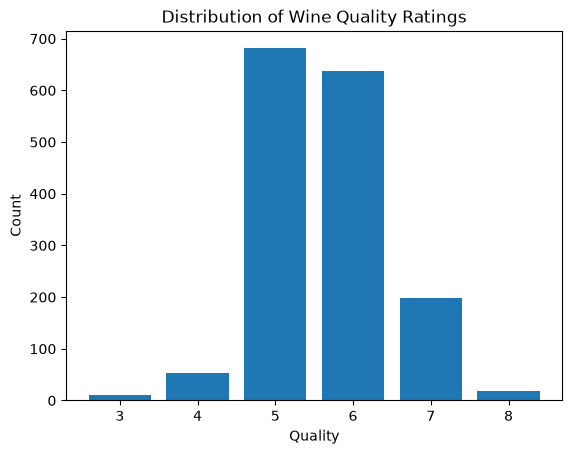

In [10]:
plt.bar(wine_data['quality'].value_counts().index, wine_data['quality'].value_counts().values)
plt.xlabel('Quality')
plt.ylabel('Count')
plt.title('Distribution of Wine Quality Ratings')

### 3. What is the average value of each feature (column) in each `quality` score level? 

In [11]:
wine_data['quality'].mean(numeric_only=True)

np.float64(5.6360225140712945)

### 4. What is the median value of each feature (column) in each `quality` score level? 

In [12]:
wine_data.groupby('quality').median(numeric_only=True)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,7.50,0.845,0.035,2.1,0.0905,6.0,15.0,0.997565,3.39,0.545,9.925
4,7.50,0.670,0.090,2.1,0.0800,11.0,26.0,0.996500,3.37,0.560,10.000
5,7.80,0.580,0.230,2.2,0.0810,15.0,47.0,0.997000,3.30,0.580,9.700
6,7.90,0.490,0.260,2.2,0.0780,14.0,35.0,0.996560,3.32,0.640,10.500
7,8.80,0.370,0.400,2.3,0.0730,11.0,27.0,0.995770,3.28,0.740,11.500
8,8.25,0.370,0.420,2.1,0.0705,7.5,21.5,0.994940,3.23,0.740,12.150


Quality scores 5 and 6 show relatively similar median values across most features.
Higher-quality wines (7 and 8) generally have higher alcohol content.

### 5. We can notice that for some features raw values differ significantly. Scale the data (except quality column) using Min-Max Scaling manually (create formula yourself). Then use built-in Min-Max Scaling function to validate results (display the resulting data frames separately).
#### Hint: you can use `pd.DataFrame(<your data>)` to display the result of the built-in function in a nicer way.

In [14]:
features = wine_data.drop(columns=['quality'])
manual_scaled = (features - features.min()) / (features.max() - features.min())
display(manual_scaled.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846


In [16]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaled_values = scaler.fit_transform(features)
scaled_df = pd.DataFrame(scaled_values,
                         columns=features.columns,
                         index=features.index)
display(scaled_df.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846


### 6. Create correlation matrix between all variables.

In [17]:
coorrelation_matrix = wine_data.corr()
display(coorrelation_matrix)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397


### 7. Plot heatmap to see correlations.

<Axes: >

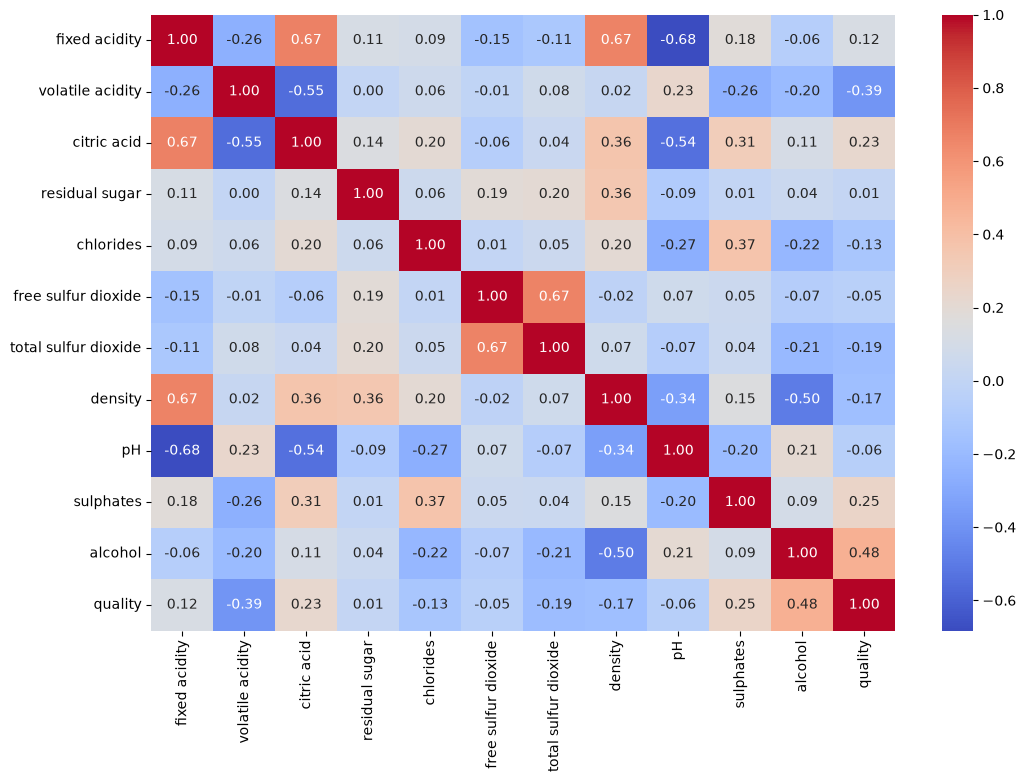

In [18]:
import seaborn as sns
plt.figure(figsize=(12, 8))
sns.heatmap(coorrelation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

### 8. Identify the first and last 10% of data outliers in `alcohol`

In [21]:
lower_limit = wine_data['alcohol'].quantile(0.10)
upper_limit = wine_data['alcohol'].quantile(0.90)

alcohol_outliers= wine_data[(wine_data['alcohol'] < lower_limit) | (wine_data['alcohol'] > upper_limit)]
display(alcohol_outliers)
print("lower_limit:", lower_limit)
print("upper_limit:", upper_limit)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
10,6.7,0.580,0.08,1.8,0.097,15.0,65.0,0.99590,3.28,0.54,9.2,5
13,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,5
14,8.9,0.620,0.18,3.8,0.176,52.0,145.0,0.99860,3.16,0.88,9.2,5
15,8.9,0.620,0.19,3.9,0.170,51.0,148.0,0.99860,3.17,0.93,9.2,5
18,7.4,0.590,0.08,4.4,0.086,6.0,29.0,0.99740,3.38,0.50,9.0,4
...,...,...,...,...,...,...,...,...,...,...,...,...
1568,7.0,0.560,0.13,1.6,0.077,25.0,42.0,0.99629,3.34,0.59,9.2,5
1570,6.4,0.360,0.53,2.2,0.230,19.0,35.0,0.99340,3.37,0.93,12.4,6
1573,6.0,0.580,0.20,2.4,0.075,15.0,50.0,0.99467,3.58,0.67,12.5,6
1588,7.2,0.660,0.33,2.5,0.068,34.0,102.0,0.99414,3.27,0.78,12.8,6


lower_limit: 9.3
upper_limit: 12.0


### 9. Plot boxplots for all columns (except quality), use figure size 15x6. You can use both original and scaled data for this task. Try to interpret the data for one feature of your choice and write your observations.

<function matplotlib.pyplot.show(close=None, block=None)>

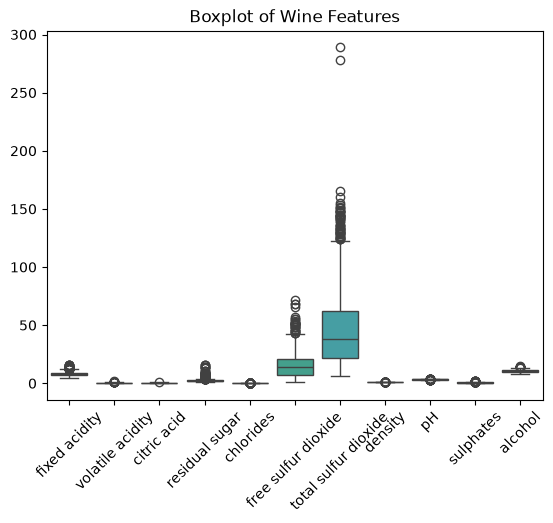

In [22]:
plt.Figure(figsize=(15, 6))
sns.boxplot(data=wine_data.drop(columns=['quality']))
plt.xticks(rotation=45)
plt.title('Boxplot of Wine Features')
plt.show

###Alcohol feature shows several outliers in the boxplot. Most observations are concentrated within the central range, while some values lie outside the whiskers. These outliers represent wines with unusually low or high alcohol content compared to the majority of the dataset.


### 10. Plot boxplot of Ph for each quality type.

<function matplotlib.pyplot.show(close=None, block=None)>

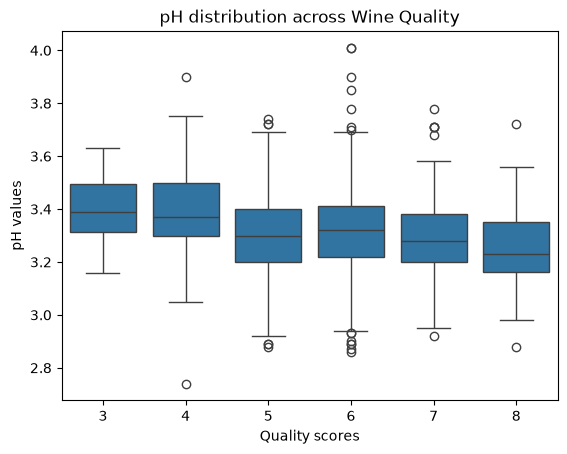

In [23]:
plt.Figure(figsize=(10, 6))
sns.boxplot(data=wine_data, x='quality', y='pH')
plt.title('pH distribution across Wine Quality')
plt.xlabel('Quality scores')
plt.ylabel('pH values')
plt.show

### 11. Plot scatter plot for `quality` and column with strongest correlation to it. Does alcohol influence the quality of the wine?

strongest_feature: alcohol


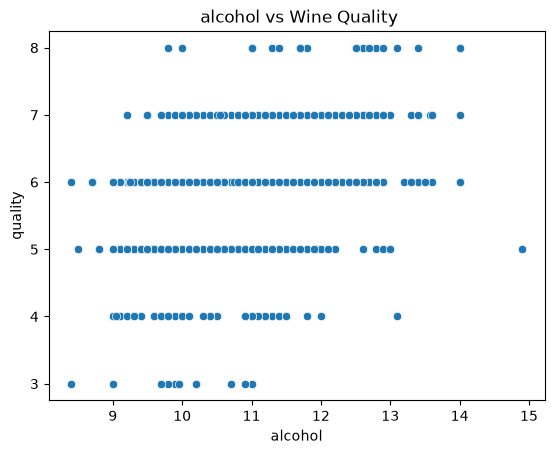

In [24]:
correlation_matrix= wine_data.corr()['quality'].drop('quality')
strongest_feature= correlation_matrix.abs().idxmax()
print("strongest_feature:", strongest_feature)

sns.scatterplot(data=wine_data, x=strongest_feature, y='quality')
plt.title(f' {strongest_feature} vs Wine Quality')
plt.show()


### Observation

Alcohol has the strongest positive correlation with wine quality. The scatter plot shows that wines with higher alcohol content generally tend to have higher quality scores this suggests that alcohol content is an important predictor of wine quality however, correlation does not necessarily imply causation, as other chemical properties also contribute to wine quality.

### 12. Plot scatter plot for any two columns and color it by `quality` number. Add color legend and write your observations.

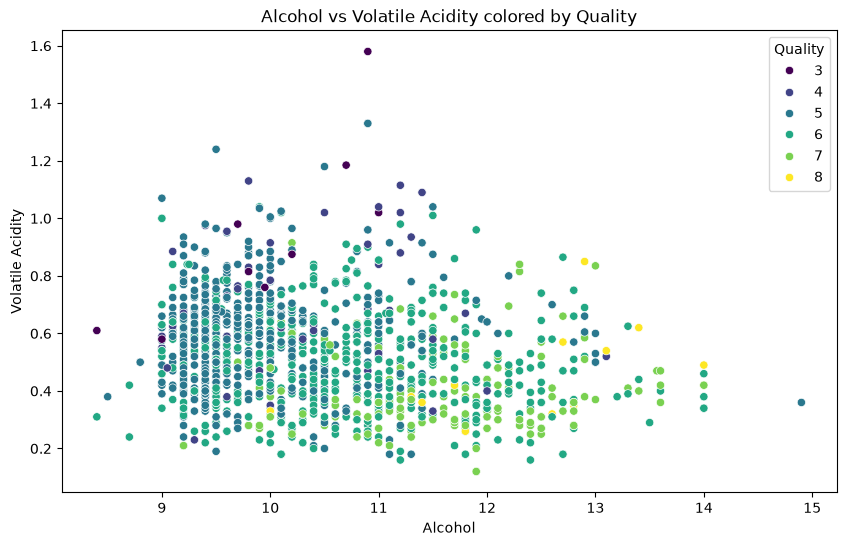

In [25]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=wine_data,
    x='alcohol',
    y='volatile acidity',
    hue='quality',
    palette='viridis'
)
plt.title('Alcohol vs Volatile Acidity colored by Quality')
plt.xlabel('Alcohol')
plt.ylabel('Volatile Acidity')
plt.legend(title= 'Quality')
plt.show()

###

The scatter plot shows that higher-quality wines have higher alcohol content and lower volatile acidity. While, the points overlap significantly across different quality levels, suggesting that multiple chemical features contribute to wine quality rather than just two features.

###

### 13. Create X, y for independent variables (all except `quality`) and target variable `quality`, perform k-fold k=3 split on them and calculate and print out the length of training set and testing set for each fold

In [26]:
X= wine_data.drop(columns=['quality'])
y= wine_data['quality']

In [27]:
from sklearn.model_selection import KFold
kf = KFold(n_splits=3, shuffle=True, random_state=42)
for fold, (train_idx, test_idx) in enumerate(kf.split(X), start=1):
    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    print(f"Fold {fold}:")
    print(f"Training Set: {len(train_idx)}")
    print(f"Testing set: {len(test_idx)}")
    print()

Fold 1:
Training Set: 1066
Testing set: 533

Fold 2:
Training Set: 1066
Testing set: 533

Fold 3:
Training Set: 1066
Testing set: 533



### 14. Create two new features:
- Sulfur dioxide ration (`free sulfur dioxide` / `total sulfur dioxide`)
- Total acidity (`fixed acidity` + `volatile acidity` + `citric acid`)

In [29]:
#sulphur dioxide ratio
wine_data['sulfur_dioxide_ratio'] = (
    wine_data['free sulfur dioxide'] /
    wine_data['total sulfur dioxide']
)

# total acidity
wine_data['total_acidity'] = (
    wine_data['fixed acidity'] +
    wine_data['volatile acidity'] +
    wine_data['citric acid']
)
display(wine_data.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,sulfur_dioxide_ratio,total_acidity
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0.323529,8.10
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0.373134,8.68
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0.277778,8.60
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0.283333,12.04
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0.323529,8.10


### 15. Create a sample dataset with dates for a whole week. Extract day of the week with `dayofweek` function (0=Monday, 6=Sunday). Additionally flag weekends by creating another new `is_weekend` feature.

In [32]:
dates = pd.date_range(start='2026-11-02', periods=7, freq='D')

df = pd.DataFrame({'date': dates})

# Extracting day of the week 0=Monday, 6=Sunday
df['dayofweek'] = df['date'].dt.dayofweek

# Creating weekend flag (Saturday=5, Sunday=6)
df['is_weekend'] = df['dayofweek'].isin([5, 6])

display(df)

C:\Users\ali.a.mehdi\AppData\Local\Temp\ipykernel_28096\48109048.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['dayofweek'] = df['date'].dt.dayofweek


,date,dayofweek,is_weekend
0,2026-11-02,0,False
1,2026-11-03,1,False
2,2026-11-04,2,False
3,2026-11-05,3,False
4,2026-11-06,4,False
5,2026-11-07,5,True
6,2026-11-08,6,True
